# Classical GNNs on QM9: GINE, GCN and GAT

This notebook trains the **classical** side of the comparison on exactly the same molecules, graphs, splits and target as the quantum GNN.

| Experiment | Data | Why |
|---|---|---|
| A. GINE, GCN, GAT | 10k subset, random split | The fair baseline for the quantum model (same training data), and an architecture comparison |
| B. GINE | 10k subset, scaffold split | Generalisation to unseen ring systems |
| C. GINE | **full** 104k training set | Checks the pipeline against the literature (≈ 0.12 eV for a 2D GCN, Therrien et al. 2025) and shows how much more data helps |

All three experiments are scored on the **same 2,000 subset test molecules**. These are a subset of the full test set, because the subset was drawn inside the original split. Experiment C also reports the full 13,075-molecule test set.

**Graphs:** heavy-atom graphs with 23 node features and 6 edge features, built by `qm9_graphs.py`. That file is the same featuriser as `QGNN_01_Subset_GraphDataset.ipynb`; section 1 checks this.

**Training (all runs):** Adam (lr 1e-3) on the MSE of the scaled target, learning rate halved when validation stops improving, early stopping on validation MAE in eV, and the best epoch's weights restored. The test set is only used for final scoring.

## 0. Setup

In [1]:
# Run once if packages are missing
# !pip install torch torch_geometric rdkit pandas numpy matplotlib

In [2]:
import os, json, time, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GINEConv, GCNConv, GATv2Conv, global_mean_pool

import qm9_graphs as G

torch.set_num_threads(max(1, (os.cpu_count() or 2) // 2))
print("torch", torch.__version__, "| threads", torch.get_num_threads())

/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


torch 2.14.1+cu130 | threads 1


In [3]:
GRAPH_DIR = os.path.join("processed", "graphs")
RES_DIR   = "results"
os.makedirs(RES_DIR, exist_ok=True)

# Training budget. These values fit a laptop CPU; on a GPU raise them (e.g. 300 epochs for the full data)
SUBSET_EPOCHS, SUBSET_PATIENCE = 60, 10
FULL_EPOCHS,   FULL_PATIENCE   = 30, 8
BATCH  = 64
HIDDEN, LAYERS = 128, 4
SEEDS  = [0, 1, 2]

meta = json.load(open(os.path.join(GRAPH_DIR, "qm9_gap_subset_meta.json")))
Y_MEAN, Y_STD = meta["y_mean_eV"], meta["y_std_eV"]
print(f"target scaling: mean {Y_MEAN:.4f} eV, std {Y_STD:.4f} eV")

target scaling: mean 6.8583 eV, std 1.2837 eV


## 1. Load the subset graphs and check the featuriser

The subset graphs come from notebook 01. For experiment C, the same featuriser (`qm9_graphs.py`) also builds graphs for all 130,745 molecules. The cell below rebuilds 200 subset molecules with `qm9_graphs.py` and checks that they are identical to the saved ones.

In [4]:
sub_ds = G.GraphSet.from_file(os.path.join(GRAPH_DIR, "qm9_gap_subset_graphs.pt"))
splits = sub_ds.extra["splits"]
index = pd.read_csv(os.path.join(GRAPH_DIR, "qm9_gap_subset_index.csv"), index_col="sub_idx")
print(len(sub_ds), "subset graphs |", {f"{k}/{s}": len(v) for k, d in splits.items() for s, v in d.items()})

for i in range(0, 14000, 70):
    a = sub_ds[i]
    b = G.smiles_to_data(a.smiles, a.y.item(), a.y_eV.item(), a.row.item())
    assert torch.equal(a.x, b.x) and torch.equal(a.edge_index, b.edge_index) and torch.equal(a.edge_attr, b.edge_attr)
print("qm9_graphs.py reproduces the saved subset graphs exactly (200 molecules checked)")

14000 subset graphs | {'random/train': 10000, 'random/val': 2000, 'random/test': 2000, 'scaffold/train': 10000, 'scaffold/val': 2000, 'scaffold/test': 2000}
qm9_graphs.py reproduces the saved subset graphs exactly (200 molecules checked)


## 2. Models

All three share the same skeleton: embed the atoms (23 → 128), run 4 message-passing layers with residual connections and batch norm, average the atom vectors into one molecule vector (mean pooling, because the gap is intensive), and predict the scaled gap with a 2-layer MLP head. Only the message-passing layer changes:

| Layer | How an atom combines its neighbours | Uses bond features? |
|---|---|---|
| **GINE** (Graph Isomorphism Network with edges) | sum of ReLU(neighbour + bond embedding), then an MLP | yes |
| **GCN** (Graph Convolutional Network) | degree-normalised average of neighbours | no (structure only) |
| **GAT** (Graph Attention, v2) | attention-weighted sum, with attention computed from atom and bond features | yes |

In [5]:
class GNN(nn.Module):
    def __init__(self, kind="gine", node_dim=23, edge_dim=6, hidden=HIDDEN, layers=LAYERS, heads=4):
        super().__init__()
        self.kind = kind
        self.embed = nn.Linear(node_dim, hidden)
        convs = []
        for _ in range(layers):
            if kind == "gine":
                convs.append(GINEConv(nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, hidden)),
                                      edge_dim=edge_dim))
            elif kind == "gcn":
                convs.append(GCNConv(hidden, hidden))
            elif kind == "gat":
                convs.append(GATv2Conv(hidden, hidden // heads, heads=heads, edge_dim=edge_dim))
        self.convs = nn.ModuleList(convs)
        self.norms = nn.ModuleList([nn.BatchNorm1d(hidden) for _ in range(layers)])
        self.head = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, d):
        h = self.embed(d.x)
        for conv, norm in zip(self.convs, self.norms):
            m = conv(h, d.edge_index) if self.kind == "gcn" else conv(h, d.edge_index, d.edge_attr)
            h = h + torch.relu(norm(m))
        return self.head(global_mean_pool(h, d.batch)).squeeze(1)

for k in ["gine", "gcn", "gat"]:
    print(f"{k.upper():5s} {sum(p.numel() for p in GNN(k).parameters()):,} parameters")

GINE  156,417 parameters
GCN   86,785 parameters


GAT   156,929 parameters


In [6]:
@torch.no_grad()
def predict(model, ds, batch=512):
    model.eval()
    return torch.cat([model(d) for d in DataLoader(ds, batch_size=batch)])

def targets(ds, batch=4096):
    return torch.cat([d.y.squeeze(1) for d in DataLoader(ds, batch_size=batch)])

def train(model, train_ds, val_ds, epochs, patience, seed, lr=1e-3, log_every=10):
    torch.manual_seed(seed)
    loader = DataLoader(train_ds, batch_size=BATCH, shuffle=True,
                        generator=torch.Generator().manual_seed(seed))
    y_val = targets(val_ds)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, factor=0.5, patience=4)
    best, best_state, bad, hist = float("inf"), None, 0, {"train_mae": [], "val_mae": []}
    t0 = time.perf_counter()
    for ep in range(1, epochs + 1):
        model.train(); err, n = 0.0, 0
        for d in loader:
            opt.zero_grad()
            pred = model(d)
            loss = nn.functional.mse_loss(pred, d.y.squeeze(1))
            loss.backward(); opt.step()
            err += (pred.detach() - d.y.squeeze(1)).abs().sum().item(); n += d.num_graphs
        va = (predict(model, val_ds) - y_val).abs().mean().item() * Y_STD
        hist["train_mae"].append(err / n * Y_STD); hist["val_mae"].append(va)
        sched.step(va)
        if va < best - 1e-4:
            best, best_state, bad = va, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
        if log_every and (ep == 1 or ep % log_every == 0):
            print(f"  epoch {ep:3d} | train {hist['train_mae'][-1]:.3f} | val {va:.3f} eV | {time.perf_counter() - t0:.0f}s")
        if bad >= patience:
            break
    model.load_state_dict(best_state)
    hist.update(best_val=best, epochs=ep, time_s=time.perf_counter() - t0)
    return model, hist

RESULTS, HISTORIES, TEST_PREDS = [], {}, {}
N_F = pd.read_csv(os.path.join("processed", "qm9_clean.csv"), usecols=["n_F"])["n_F"].values   # fluorine count per row

def score(name, data_name, split_name, seed, model, hist, test_ds, test_label="subset test"):
    pred = predict(model, test_ds)
    err = (pred - targets(test_ds)).abs() * Y_STD
    rows = torch.cat([d.row for d in DataLoader(test_ds, batch_size=4096)]).numpy()
    has_F = torch.tensor(N_F[rows] > 0)
    row = {"model": name, "train_data": data_name, "split": split_name, "seed": seed, "test_set": test_label,
           "params": sum(p.numel() for p in model.parameters()), "val_mae_eV": hist["best_val"],
           "test_mae_eV": err.mean().item(),
           "test_mae_F_eV": err[has_F].mean().item() if has_F.any() else np.nan,
           "test_mae_noF_eV": err[~has_F].mean().item(), "epochs": hist["epochs"], "train_time_s": hist["time_s"]}
    RESULTS.append(row)
    TEST_PREDS[(name, data_name, split_name, seed, test_label)] = (rows, pred.numpy() * Y_STD + Y_MEAN)
    print(f"  -> {name} | {data_name} | {split_name} | seed {seed} | {test_label}: "
          f"test MAE {row['test_mae_eV']:.3f} eV (val {row['val_mae_eV']:.3f}, {row['epochs']} epochs, {row['train_time_s']:.0f}s)")
    return row

## 3. Experiment A: GINE, GCN and GAT on the 10k subset (random split)

GINE is trained with 3 seeds. GCN and GAT get 1 seed each, as an architecture comparison.

In [7]:
sp = splits["random"]
tr_ds, va_ds, te_ds = sub_ds[sp["train"]], sub_ds[sp["val"]], sub_ds[sp["test"]]
for kind, seeds in [("gine", SEEDS), ("gcn", [0]), ("gat", [0])]:
    for seed in seeds:
        torch.manual_seed(seed)
        model, hist = train(GNN(kind), tr_ds, va_ds, SUBSET_EPOCHS, SUBSET_PATIENCE, seed, log_every=0)
        HISTORIES[(kind.upper(), "subset", "random", seed)] = hist
        score(kind.upper(), "10k subset", "random", seed, model, hist, te_ds)

  -> GINE | 10k subset | random | seed 0 | subset test: test MAE 0.173 eV (val 0.175, 60 epochs, 168s)


  -> GINE | 10k subset | random | seed 1 | subset test: test MAE 0.173 eV (val 0.173, 60 epochs, 141s)


  -> GINE | 10k subset | random | seed 2 | subset test: test MAE 0.171 eV (val 0.169, 60 epochs, 140s)


  -> GCN | 10k subset | random | seed 0 | subset test: test MAE 0.197 eV (val 0.193, 60 epochs, 113s)


  -> GAT | 10k subset | random | seed 0 | subset test: test MAE 0.184 eV (val 0.182, 44 epochs, 188s)


## 4. Experiment B: GINE on the 10k subset, scaffold split

In [8]:
sp = splits["scaffold"]
tr_s, va_s, te_s = sub_ds[sp["train"]], sub_ds[sp["val"]], sub_ds[sp["test"]]
for seed in SEEDS:
    torch.manual_seed(seed)
    model, hist = train(GNN("gine"), tr_s, va_s, SUBSET_EPOCHS, SUBSET_PATIENCE, seed, log_every=0)
    HISTORIES[("GINE", "subset", "scaffold", seed)] = hist
    score("GINE", "10k subset", "scaffold", seed, model, hist, te_s)

  -> GINE | 10k subset | scaffold | seed 0 | subset test: test MAE 0.311 eV (val 0.274, 38 epochs, 86s)


  -> GINE | 10k subset | scaffold | seed 1 | subset test: test MAE 0.316 eV (val 0.296, 20 epochs, 45s)


  -> GINE | 10k subset | scaffold | seed 2 | subset test: test MAE 0.319 eV (val 0.281, 40 epochs, 90s)


## 5. Experiment C: GINE on the full training set (104,595 molecules)

This builds graphs for all 130,745 molecules (about a minute, cached to `processed/graphs/qm9_gap_full_graphs.pt`) and uses the original train/val/test indices from the preprocessing notebook. The model is scored on the full test set and on the 2,000-molecule subset test set, which lies inside it.

In [9]:
FULL_PATH = os.path.join(GRAPH_DIR, "qm9_gap_full_graphs.pt")
proc = np.load(os.path.join("processed", "qm9_gap_eV_processed.npz"))
idx_full = {"train": proc["idx_tr"], "val": proc["idx_va"], "test": proc["idx_te"]}

if os.path.exists(FULL_PATH):
    full_ds = G.GraphSet.from_file(FULL_PATH)
else:
    t0 = time.perf_counter()
    df = pd.read_csv(os.path.join("processed", "qm9_clean.csv"), usecols=["can_smiles", "gap_eV"])
    graphs = [G.smiles_to_data(s, (g - Y_MEAN) / Y_STD, g, r)
              for r, (s, g) in enumerate(zip(df["can_smiles"], df["gap_eV"]))]
    data_all, slices_all = G.InMemoryDataset.collate(graphs)
    torch.save({"data": data_all, "slices": slices_all}, FULL_PATH)
    full_ds = G.GraphSet(data_all, slices_all)
    print(f"built {len(graphs):,} graphs in {time.perf_counter() - t0:.0f}s")
print(len(full_ds), "graphs")

# graph i in full_ds is row i of qm9_clean.csv, so the original indices apply directly
ftr, fva, fte = (full_ds[torch.tensor(idx_full[s])] for s in ["train", "val", "test"])
assert torch.equal(sub_ds[splits["random"]["test"]][0].x, full_ds[int(sub_ds[splits["random"]["test"]][0].row)].x)
print("train / val / test:", len(ftr), len(fva), len(fte))

130745 graphs
train / val / test: 104595 13075 13075


In [10]:
torch.manual_seed(0)
model_full, hist_full = train(GNN("gine"), ftr, fva, FULL_EPOCHS, FULL_PATIENCE, seed=0, log_every=5)
HISTORIES[("GINE", "full", "random", 0)] = hist_full
score("GINE", "full 104k", "random", 0, model_full, hist_full, te_ds, "subset test")
score("GINE", "full 104k", "random", 0, model_full, hist_full, fte, "full test (13,075)")

  epoch   1 | train 0.300 | val 0.291 eV | 33s


  epoch   5 | train 0.199 | val 0.217 eV | 125s


  epoch  10 | train 0.167 | val 0.164 eV | 242s


  epoch  15 | train 0.150 | val 0.146 eV | 362s


  epoch  20 | train 0.139 | val 0.136 eV | 480s


  epoch  25 | train 0.131 | val 0.136 eV | 601s


  epoch  30 | train 0.125 | val 0.131 eV | 721s


  -> GINE | full 104k | random | seed 0 | subset test: test MAE 0.131 eV (val 0.128, 30 epochs, 721s)


  -> GINE | full 104k | random | seed 0 | full test (13,075): test MAE 0.130 eV (val 0.128, 30 epochs, 721s)


{'model': 'GINE',
 'train_data': 'full 104k',
 'split': 'random',
 'seed': 0,
 'test_set': 'full test (13,075)',
 'params': 156417,
 'val_mae_eV': 0.1283316524317318,
 'test_mae_eV': 0.1301380693912506,
 'test_mae_F_eV': 0.12815886735916138,
 'test_mae_noF_eV': 0.1301639825105667,
 'epochs': 30,
 'train_time_s': 721.1189838539997}

## 6. Results

In [11]:
res = pd.DataFrame(RESULTS)
res.to_csv(os.path.join(RES_DIR, "classical_results.csv"), index=False)

summary = (res.groupby(["model", "train_data", "split", "test_set"], sort=False)
              .agg(params=("params", "first"), seeds=("seed", "count"),
                   test_mae=("test_mae_eV", "mean"), test_std=("test_mae_eV", "std"),
                   mae_with_F=("test_mae_F_eV", "mean"), mae_without_F=("test_mae_noF_eV", "mean"),
                   epochs=("epochs", "mean"), time_s=("train_time_s", "mean"))
              .round(3))
summary

params  seeds  test_mae  \
model train_data split    test_set                                      
GINE  10k subset random   subset test         156417      3     0.173   
GCN   10k subset random   subset test          86785      1     0.197   
GAT   10k subset random   subset test         156929      1     0.184   
GINE  10k subset scaffold subset test         156417      3     0.316   
      full 104k  random   subset test         156417      1     0.131   
                          full test (13,075)  156417      1     0.130   

                                              test_std  mae_with_F  \
model train_data split    test_set                                   
GINE  10k subset random   subset test            0.001       0.181   
GCN   10k subset random   subset test              NaN       0.250   
GAT   10k subset random   subset test              NaN       0.183   
GINE  10k subset scaffold subset test            0.004       0.061   
      full 104k  random   subset test              NaN       0.122   
                          full test (13,075)       NaN       0.128   

                                              mae_without_F  epochs   time_s  
model train_data split    test_set                                            
GINE  10k subset random   subset test                 0.172  60.000  149.822  
GCN   10k subset random   subset test                 0.196  60.000  113.392  
GAT   10k subset random   subset test                 0.184  44.000  188.391  
GINE  10k subset scaffold subset test                 0.316  32.667   73.878  
      full 104k  random   subset test                 0.131  30.000  721.119  
                          full test (13,075)          0.130  30.000  721.119

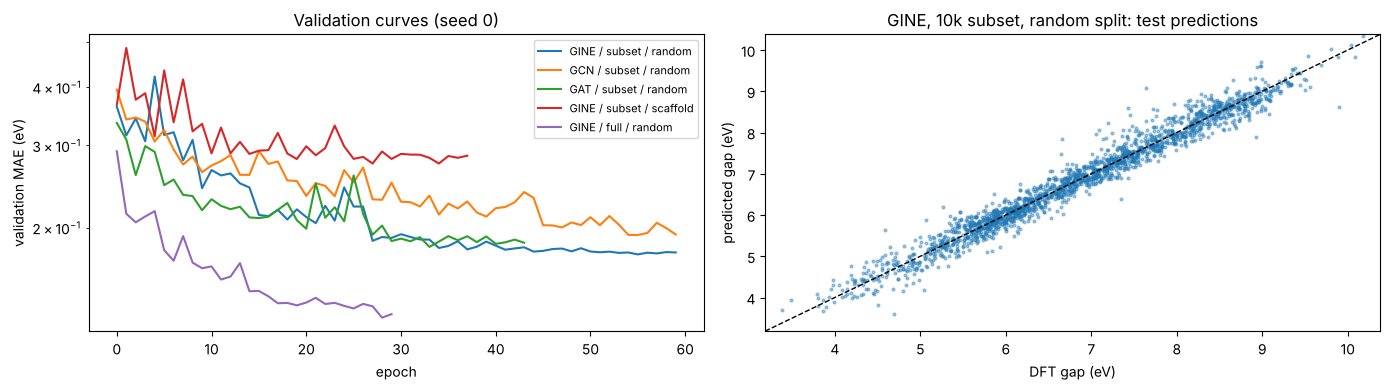

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for key, h in HISTORIES.items():
    if key[3] == 0:
        axes[0].plot(h["val_mae"], label=" / ".join(map(str, key[:3])))
axes[0].set_yscale("log"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation MAE (eV)")
axes[0].set_title("Validation curves (seed 0)"); axes[0].legend(fontsize=8)

rows, pred = TEST_PREDS[("GINE", "10k subset", "random", 0, "subset test")]
truth = targets(te_ds).numpy() * Y_STD + Y_MEAN
axes[1].scatter(truth, pred, s=4, alpha=0.4)
lim = [truth.min() - 0.2, truth.max() + 0.2]
axes[1].plot(lim, lim, "k--", lw=1); axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("DFT gap (eV)"); axes[1].set_ylabel("predicted gap (eV)")
axes[1].set_title("GINE, 10k subset, random split: test predictions")
plt.tight_layout(); plt.show()

In [13]:
def m(model, data, sp, test="subset test"):
    s = res[(res.model == model) & (res.train_data == data) & (res.split == sp) & (res.test_set == test)]["test_mae_eV"]
    return s.mean(), s.std()

g_r, g_r_sd = m("GINE", "10k subset", "random"); g_s, g_s_sd = m("GINE", "10k subset", "scaffold")
print(f"• GINE, 10k subset, random split:   {g_r:.3f} ± {g_r_sd:.3f} eV (3 seeds)")
print(f"• GINE, 10k subset, scaffold split: {g_s:.3f} ± {g_s_sd:.3f} eV  ({g_s / g_r:.2f}x the random-split error)")
print(f"• GCN {m('GCN', '10k subset', 'random')[0]:.3f} eV, GAT {m('GAT', '10k subset', 'random')[0]:.3f} eV (1 seed each)")
print(f"• GINE, full 104k training set: {m('GINE', 'full 104k', 'random')[0]:.3f} eV on the subset test, "
      f"{m('GINE', 'full 104k', 'random', 'full test (13,075)')[0]:.3f} eV on the full test set "
      f"({FULL_EPOCHS} epochs max; literature 2D GCN ≈ 0.12 eV after much longer training)")

• GINE, 10k subset, random split:   0.173 ± 0.001 eV (3 seeds)
• GINE, 10k subset, scaffold split: 0.316 ± 0.004 eV  (1.83x the random-split error)
• GCN 0.197 eV, GAT 0.184 eV (1 seed each)
• GINE, full 104k training set: 0.131 eV on the subset test, 0.130 eV on the full test set (30 epochs max; literature 2D GCN ≈ 0.12 eV after much longer training)
